<a href="https://colab.research.google.com/github/MarcoGuedes/TCC-2026/blob/main/TCC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nova seção

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential, Model
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, UpSampling2D, Conv2DTranspose, Flatten, Reshape
from tensorflow.keras.datasets import mnist
from tensorflow.keras.optimizers import AdamW
import sys
import time
from pathlib import Path

In [ ]:
IMG_SIZE = 96
CHANNELS = 3
BATCH_SIZE = 32
EPOCHS = 100

PATIENCE = 10
TRAIN_DS = 0.8
VAL_DS = 0.1
TEST_DS = 0.1

SEED = 41

LATENT_DIMS = [1024, 1536, 2048, 3072]

In [ ]:
# Create directories for checkpoints
os.makedirs('./cae_with_disc_checkpoint', exist_ok=True)
os.makedirs('./cae_no_disc_checkpoint', exist_ok=True)
os.makedirs('./disc_checkpoint', exist_ok=True)

CAE_WITH_DISC_CHECKPOINT_DIR = './cae_disc_later_checkpoint/'
CAE_NO_DISC_CHECKPOINT_DIR = './cae_no_disc_checkpoint/'
DISC_CHECKPOINT_DIR = './disc_checkpoint/'

In [ ]:
def load_stl10_data():
    # Load training images correctly as uint8
    images = np.fromfile("train_X.bin", dtype=np.uint8)
    # Reshape and transpose to (N, H, W, C)
    images = images.reshape(-1, 3, 96, 96).transpose(0, 2, 3, 1)

    # Normalize images to [0, 1] for display
    images = images.astype(np.float32) / 255.0
    idx_train = int(TRAIN_DS*len(images))
    idx_val = int((TRAIN_DS + VAL_DS)*len(images))
    idx_test = int((TRAIN_DS + VAL_DS + TEST_DS)*len(images))

    train_imgs = images[:idx_train]
    val_imgs = images[idx_train:idx_val]
    test_imgs = images[idx_val:idx_test]

    rng = np.random.default_rng(seed=SEED)
    rng.shuffle(images)

    return train_imgs, val_imgs, test_imgs

In [ ]:
train_imgs, val_imgs, test_imgs = load_stl10_data()
print("Train images shape:", train_imgs.shape)
print("Validation images shape:", val_imgs.shape)
print("Test images shape:", test_imgs.shape)

Train images shape: (4000, 96, 96, 3)
Validation images shape: (500, 96, 96, 3)
Test images shape: (500, 96, 96, 3)


In [ ]:
# bpp_jpeg.py
import io
import numpy as np
from PIL import Image

def bpp_jpeg(images, quality=50):
    bpps = []
    for img in images:
        buffer = io.BytesIO()
        Image.fromarray((img * 255).astype("uint8")).save(
            buffer, format="JPEG", quality=quality
        )
        bits = buffer.tell() * 8
        h, w, _ = img.shape
        bpps.append(bits / (h * w))
    return float(np.mean(bpps))

imagem = train_imgs[0]
imagens_teste = np.expand_dims(imagem, axis=0)

for q in [5, 10, 20, 35, 50, 70, 85]:
    print(f"quality={q} -> bpp={bpp_jpeg(imagens_teste, quality=q):.3f}")

quality=5 -> bpp=0.826
quality=10 -> bpp=0.996
quality=20 -> bpp=1.244
quality=35 -> bpp=1.542
quality=50 -> bpp=1.797
quality=70 -> bpp=2.247
quality=85 -> bpp=3.036


In [ ]:
tf.keras.optimizers.AdamW = AdamW(
    learning_rate=0.001,
    weight_decay=0.0001,
    beta_1=0.5,
    beta_2=0.999,
    epsilon=1e-07,
)

In [ ]:

def build_encoder(latent_dim=256):
    return Sequential([
        Conv2D(32, 4, strides=2, padding="same", activation="leaky_relu",# 96 -> 48
               input_shape=(IMG_SIZE, IMG_SIZE, CHANNELS),
               use_bias=False,),
        Conv2D(64, 4, strides=2, padding="same", activation="leaky_relu"),# 48 -> 24
        Conv2D(128, 4, strides=2, padding="same", activation="leaky_relu"),# 24 -> 12
        Conv2D(256, 4, strides=2, padding="same", activation="leaky_relu"),# 12 -> 6 (latente: 6x6x256)
        Flatten(),
        Dense(latent_dim, activation="leaky_relu")
    ], name="encoder")

def build_decoder(latent_dim=256):
    return Sequential([
        Dense(6 * 6 * 256, activation="leaky_relu", input_shape=(latent_dim,)),
        Reshape((6, 6, 256)),
        Conv2DTranspose(128, 4, strides=2, padding="same", activation="leaky_relu"),# 6 -> 12
        Conv2DTranspose(64, 4, strides=2, padding="same", activation="leaky_relu"),# 12 -> 24
        Conv2DTranspose(32, 4, strides=2, padding="same", activation="leaky_relu"),# 24 -> 48
        Conv2DTranspose(CHANNELS, 4, strides=2, padding="same", activation="sigmoid"),# 48 -> 96
    ], name="decoder")

def build_cae(latent_dim=256):
    cae = Sequential([build_encoder(latent_dim), build_decoder(latent_dim)], name="cae")
    cae.compile(optimizer="adamw", loss="mae")
    return cae

def build_discriminator():
    discriminator = Sequential([
        Conv2D(64, 4, strides=2, padding="same", activation="leaky_relu",
               input_shape=(IMG_SIZE, IMG_SIZE, CHANNELS)),
        Conv2D(128, 4, strides=2, padding="same", activation="leaky_relu"),
        Conv2D(256, 4, strides=2, padding="same", activation="leaky_relu"),
        Flatten(),
        Dense(1, activation="sigmoid"),
    ], name="discriminator")
    discriminator.compile(optimizer="adamw", loss="mae")
    return discriminator


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "cae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ encoder (Sequential)        │ (None, 256)           │  3,049,664 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ conv2d (Conv2D)        │ (None, 48, 48, 32)    │      1,536 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ conv2d_1 (Conv2D)      │ (None, 24, 24, 64)    │     32,832 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ conv2d_2 (Conv2D)      │ (None, 12, 12, 128)   │    131,200 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ conv2d_3 (Conv2D)      │ (None, 6, 6, 256)     │    524,544 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ flatten (Flatten)      │ (None, 9216)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ dense (Dense)          │ (None, 256)           │  2,359,552 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ decoder (Sequential)        │ (None, 96, 96, 3)     │  3,058,403 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ dense_1 (Dense)        │ (None, 9216)          │  2,368,512 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ reshape (Reshape)      │ (None, 6, 6, 256)     │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ conv2d_transpose       │ (None, 12, 12, 128)   │    524,416 │   Y   │
│ (Conv2DTranspose)           │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ conv2d_transpose_1     │ (None, 24, 24, 64)    │    131,136 │   Y   │
│ (Conv2DTranspose)           │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ conv2d_transpose_2     │ (None, 48, 48, 32)    │     32,800 │   Y   │
│ (Conv2DTranspose)           │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│    └ conv2d_transpose_3     │ (None, 96, 96, 3)     │      1,539 │   Y   │
│ (Conv2DTranspose)           │                       │            │       │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 6,108,067 (23.30 MB)

 Trainable params: 6,108,067 (23.30 MB)

 Non-trainable params: 0 (0.00 B)

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ conv2d_4 (Conv2D)           │ (None, 48, 48, 64)    │      3,136 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ conv2d_5 (Conv2D)           │ (None, 24, 24, 128)   │    131,200 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ conv2d_6 (Conv2D)           │ (None, 12, 12, 256)   │    524,544 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ flatten_1 (Flatten)         │ (None, 36864)         │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense_2 (Dense)             │ (None, 1)             │     36,865 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 695,745 (2.65 MB)

 Trainable params: 695,745 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

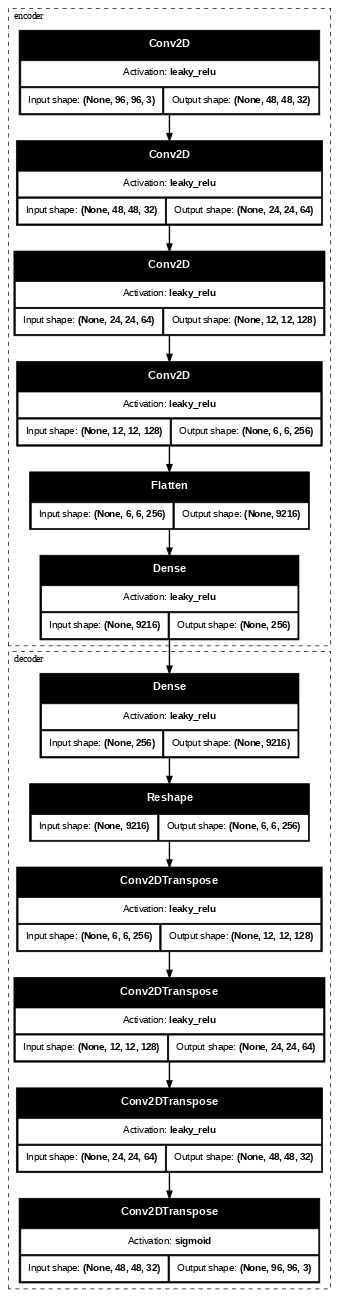

In [ ]:
cae = build_cae()
cae.summary(expand_nested=True, show_trainable=True)

discriminator_model = build_discriminator()

discriminator_model.summary(show_trainable=True)

tf.keras.utils.plot_model(
    cae,
    to_file="cae_completo.png",
    show_shapes=True,
    show_layer_activations=True,
    expand_nested=True,
    dpi=50,
)

In [ ]:
def train_cae(latent_dim, save_weight=CAE_NO_DISC_CHECKPOINT_DIR, has_disc= False, has_load = False):

  cae = build_cae(latent_dim)
  if has_load:
    cae.load_weights(save_weight+str(latent_dim)+"/cae.weights.h5")
  cae.fit(train_imgs, train_imgs, epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[tf.keras.callbacks.ModelCheckpoint(
                filepath=str("autoencoder.keras"),
                save_best_only=True,
                monitor="loss",
            ),tf.keras.callbacks.EarlyStopping(monitor="loss", patience=PATIENCE)])

  ckpt_dir = save_weight +str(latent_dim)
  os.makedirs(ckpt_dir, exist_ok=True)
  cae.save_weights(ckpt_dir+"/cae.weights.h5")
  return cae




In [ ]:
train_cae(LATENT_DIMS, CAE_NO_DISC_CHECKPOINT_DIR, False)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - loss: 0.2020
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - loss: 0.1390
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 0.1188
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - loss: 0.1067
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.1005
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0958
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 0.0910
Epoch 8/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0874
Epoch 9/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - loss: 0.0863
Epoch 10/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0825
Epoch 11/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 0.0809
Epoch 12/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 74ms/step - loss: 0.0779
Epoch 13/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 82ms/step - loss: 0.0768
Epoch 14/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 82ms/step - loss: 0.0759
Epoch 15/100
125/125 ━━━━━

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 163s 1s/step - loss: 0.1820
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 184s 1s/step - loss: 0.1259
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - loss: 0.1113
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 157s 1s/step - loss: 0.0997
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 193s 1s/step - loss: 0.0940
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - loss: 0.0899
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - loss: 0.0860
Epoch 8/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step - loss: 0.0840
Epoch 9/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 148s 1s/step - loss: 0.0806
Epoch 10/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 149s 1s/step - loss: 0.0778
Epoch 11/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 148s 1s/step - loss: 0.0773
Epoch 12/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 158s 1s/step - loss: 0.0749
Epoch 13/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 195s 1s/step - loss: 0.0728
Epoch 14/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 214s 1s/step - loss: 0.0705
Epoch 15/100
125/125 ━━━━━━━━

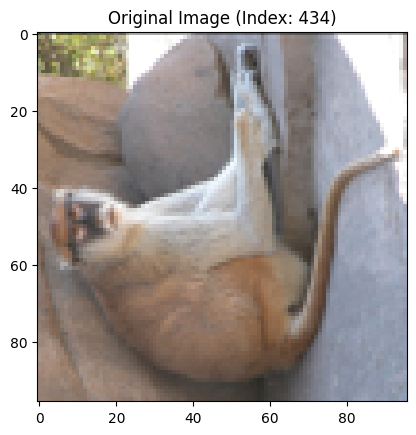

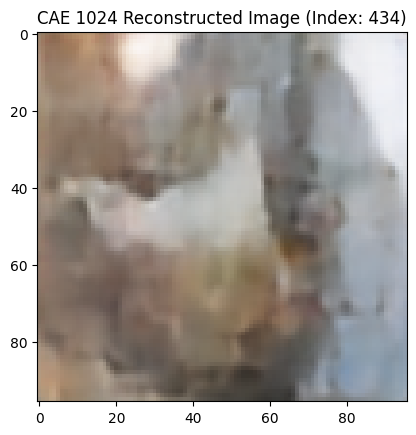

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 197s 2s/step - loss: 0.1847
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 209s 2s/step - loss: 0.1274
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - loss: 0.1107
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 196s 2s/step - loss: 0.1010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 209s 2s/step - loss: 0.0965
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 193s 2s/step - loss: 0.0914
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 198s 2s/step - loss: 0.0873
Epoch 8/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - loss: 0.0830
Epoch 9/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - loss: 0.0802
Epoch 10/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - loss: 0.0788
Epoch 11/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 211s 2s/step - loss: 0.0772
Epoch 12/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 201s 2s/step - loss: 0.0738
Epoch 13/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 225s 2s/step - loss: 0.0716
Epoch 14/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 162s 1s/step - loss: 0.0716
Epoch 15/100
125/125 ━━━━━━━━

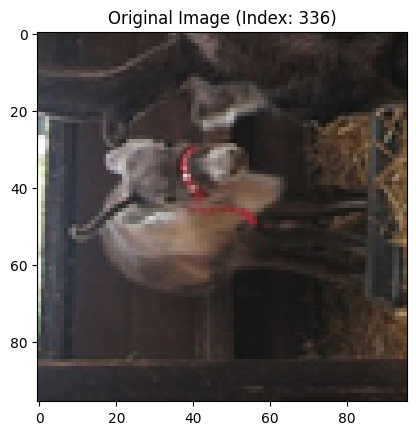

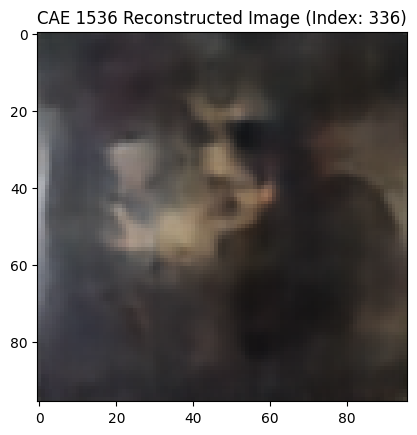

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 255s 2s/step - loss: 0.1801
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - loss: 0.1237
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 249s 2s/step - loss: 0.1094
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 246s 2s/step - loss: 0.1012
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 252s 2s/step - loss: 0.0944
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 244s 2s/step - loss: 0.0898
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 250s 2s/step - loss: 0.0873
Epoch 8/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 221s 2s/step - loss: 0.0830
Epoch 9/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 222s 2s/step - loss: 0.0808
Epoch 10/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 266s 2s/step - loss: 0.0776
Epoch 11/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 251s 2s/step - loss: 0.0763
Epoch 12/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 231s 2s/step - loss: 0.0755
Epoch 13/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 297s 2s/step - loss: 0.0724
Epoch 14/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 268s 2s/step - loss: 0.0717
Epoch 15/100
125/125 ━━━━━━━━

In [ ]:
for latent_dim in LATENT_DIMS:
    cae = train_cae(latent_dim)

    pred_cae = cae.predict(test_imgs)

    index = np.random.randint(len(test_imgs))

    plt.imshow(test_imgs[index].reshape(96,96,3))
    plt.title(f"Original Image (Index: {index})")
    plt.show()

    plt.imshow(pred_cae[index].reshape(96,96,3))
    plt.title(f"CAE {latent_dim} Reconstructed Image (Index: {index})")
    plt.show()

In [ ]:
imagens_teste = stl10[:20].astype("float32") / 255.0  # 20 imagens, ajuste o /255.0 conforme o caso acima

for q in [5, 10, 20, 35, 50, 70, 85]:
    bpp = test_bpp("jpeg", imagens_teste, jpeg_quality=q)
    print(f"quality={q} -> bpp={bpp:.3f}")

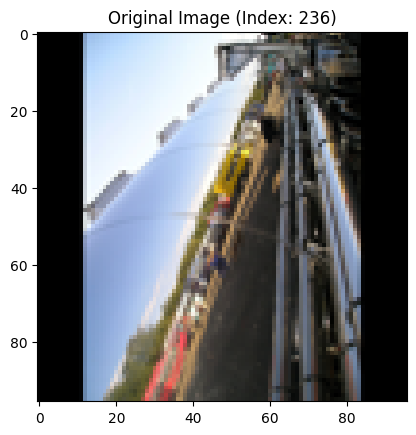

NameError: name 'pred_cae' is not defined

In [ ]:
index = np.random.randint(len(test_imgs))

plt.imshow(test_imgs[index].reshape(96,96,3))
plt.title(f"Original Image (Index: {index})")
plt.show()

plt.imshow(pred_cae[index].reshape(96,96,3))
plt.title(f"CAE Reconstructed Image (Index: {index})")
plt.show()

#print(f"Discriminator prediction for image {index}: {pred_disc[index][0]:.4f}")